# ATLAS
## Observed bank capital under historical market stress
### Research demonstration · 2 November 2026
**Question → literature → data → methods → results → verification → limitations**

30 large US banks · December 2019 baseline · June 2020 observed comparison

**Claim:** reproducible conditional stress analysis using official financial observations. The bank-to-bank contagion engine is demonstrated separately on a controlled network.

# 1 · Research question and scope
**RQ:** How does a uniform hypothetical asset impairment affect the capital buffers of a fixed cohort of large US banks, and how sensitive is capital exhaustion to the assumed market-to-asset loss mapping?

**Secondary descriptive question:** How did reported equity/assets ratios change between December 2019 and June 2020?

A bank's equity absorbs losses. For assets A and equity E, an assumed loss qA leaves E − qA. The break-even impairment is E/A. These are static accounting scenarios, not predictions of legal default.

**Scope:** no inferred bilateral network, estimated PDs, liquidity runs, fiscal/monetary responses, or forecast validation in the empirical experiment.

# 2 · Literature and the data decision
| Prior work | Relevant lesson | Atlas decision |
|---|---|---|
| Battiston et al., *Leveraging the network* (2015), DOI 10.1515/strm-2015-0005 | Uses commercial Bankscope and estimated networks | Public financials require a separate field audit |
| Macchiati et al., *Interbank network reconstruction enforcing density and reciprocity* (2024), DOI 10.1016/j.chaos.2024.115279 | Totals alone do not identify topology; method addresses binary links | Do not manufacture observed loan amounts |
| Niu et al., *iConViz* (2020), DOI 10.1109/VAST50239.2020.00013 | Private company-guarantee data; case-study evaluation | Useful design precedent; different network mechanism |
| Eisenberg & Noe (2001), DOI 10.1287/mnsc.47.2.236.9835 | Simultaneous clearing | Future model comparison; current engine is fixed-recovery |

Undermind review: 292 search results; focused full-text reading of four papers. This is a focused synthesis, not an exhaustive systematic review. No algorithmic novelty is claimed.

In [1]:
from pathlib import Path
import json, sys, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from atlas.observed import load_snapshot, cohort, stress, checksum
from atlas.market import market_data, calibration
ROOT = Path.cwd()
if not (ROOT / 'data/manifest.json').exists(): ROOT = ROOT.parent
assert (ROOT / 'data/manifest.json').exists()
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.figsize': (11, 5), 'font.size': 12, 'axes.spines.top': False, 'axes.spines.right': False})
manifest = json.loads((ROOT / 'data/manifest.json').read_text())
for item in manifest: assert checksum(ROOT / item['file']) == item['sha256']
print('Input checksums verified | Python', platform.python_version())

Input checksums verified | Python 3.12.16


# 3 · Sources, aggregation and normalization
- FDIC official API: largest 100 reporting institutions by assets at each date; raw responses retained.
- Baseline cohort: largest 30 eligible December 2019 banks, positive assets/equity, supported bank classes, no reported parent-bank consolidation (`CERTCONS=0`).
- Fixed cohort joined by FDIC certificate, not bank name. Follow-up missingness remains visible; no replacement with surviving banks.
- Monetary amounts: source USD thousands → USD millions. Ratios remain dimensionless. No z-score normalization of accounting amounts.
- `EQTOT` reconciles total assets and liabilities; `EQ` is retained in raw data but not substituted. Rounding tolerance: $2,000.
- FRED daily S&P 500 prices remain a separate time series. No daily interpolation of balance sheets.

Historical reports are retrieved in their current revised vintage; the exercise is retrospective, not a no-look-ahead backtest. Cohort sums describe these bank reports, not the entire US banking system.

In [2]:
before = load_snapshot(ROOT/'data/raw/fdic_20191231.json')
after = load_snapshot(ROOT/'data/raw/fdic_20200630.json')
banks = cohort(before, after, 30)
audit = pd.DataFrame({'date':['2019-12-31','2020-06-30'], 'raw_rows':[len(before),len(after)], 'eligible_rows':[int(before.eligible.sum()),int(after.eligible.sum())], 'max_abs_accounting_residual_USD_thousand':[before.accounting_residual_usd_thousand.abs().max(),after.accounting_residual_usd_thousand.abs().max()]})
display(audit)
print('Fixed cohort:',len(banks),' | Matched follow-up:',banks.equity_later.notna().sum())
assert len(banks)==30 and banks.bank_id.is_unique
assert banks.eligible_later.fillna(False).all(), 'Follow-up needs review'
(ROOT/'data/processed').mkdir(exist_ok=True)
banks.to_csv(ROOT/'data/processed/bank_cohort.csv',index=False)
display(banks[['bank_id','NAME','assets','equity','equity_ratio']].head(10).round(4))

,date,raw_rows,eligible_rows,max_abs_accounting_residual_USD_thousand
0,2019-12-31,100,98,1.0
1,2020-06-30,100,98,1.0


Fixed cohort: 30  | Matched follow-up: 30


,bank_id,NAME,assets,equity,equity_ratio
0,628,JPMORGAN CHASE BANK NA,2338048.000,246219.000,0.1053
1,3510,BANK OF AMERICA NA,1852983.000,212158.000,0.1145
2,3511,WELLS FARGO BANK NA,1712919.000,167393.000,0.0977
3,7213,CITIBANK NATIONAL ASSN,1453998.000,150736.000,0.1037
4,6548,U S BANK NATIONAL ASSN,486004.220,49392.503,0.1016
5,9846,TRUIST BANK,461256.000,64206.000,0.1392
6,6384,PNC BANK NATIONAL ASSN,397703.264,41794.214,0.1051
7,4297,CAPITAL ONE NATIONAL ASSN,328999.040,43055.099,0.1309
8,18409,TD BANK NATIONAL ASSN,320471.996,40195.098,0.1254
9,639,BANK OF NEW YORK MELLON,311387.000,26003.000,0.0835


# 4 · What the observed data show
The following ratios are calculated from reported financial statements. A change across dates can reflect earnings, distributions, capital issuance, balance-sheet growth, acquisitions and other factors. It does not isolate COVID's causal effect.

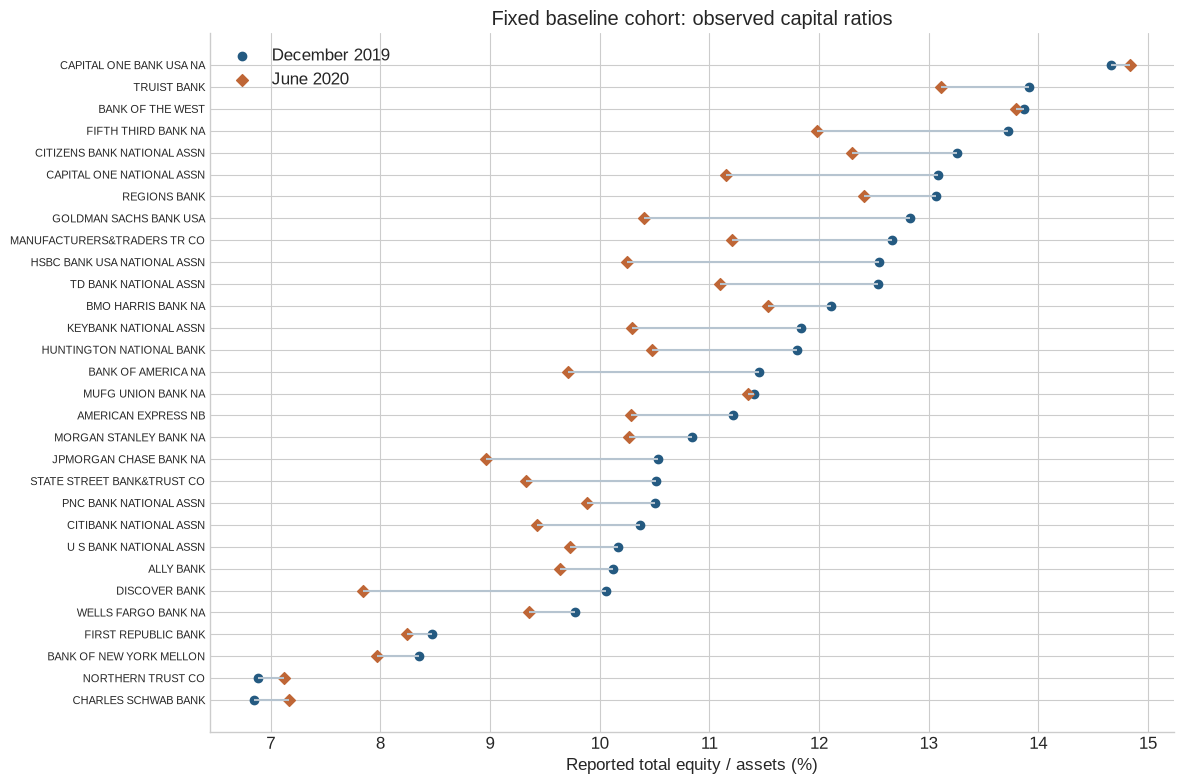

In [3]:
ordered=banks.sort_values('equity_ratio')
fig, ax=plt.subplots(figsize=(12,8))
y=np.arange(len(ordered))
ax.hlines(y,ordered.equity_ratio*100,ordered.equity_ratio_later*100,color='#b6c4d0')
ax.scatter(ordered.equity_ratio*100,y,label='December 2019',color='#245a81')
ax.scatter(ordered.equity_ratio_later*100,y,label='June 2020',color='#bf6636',marker='D')
ax.set_yticks(y,ordered.NAME,fontsize=8);ax.set_xlabel('Reported total equity / assets (%)');ax.legend()
ax.set_title('Fixed baseline cohort: observed capital ratios');plt.tight_layout();plt.show()

# 5 · Historical stress driver
The S&P 500 drawdown is observed. It is an equity price-index movement, not the loss rate on bank assets. Define q = m × D, where D is the selected-window drawdown and m is an assumed transmission multiplier. We sweep m rather than estimate it from these data.

The main sensitivity experiment uses q directly, so it remains interpretable independently of the market mapping.

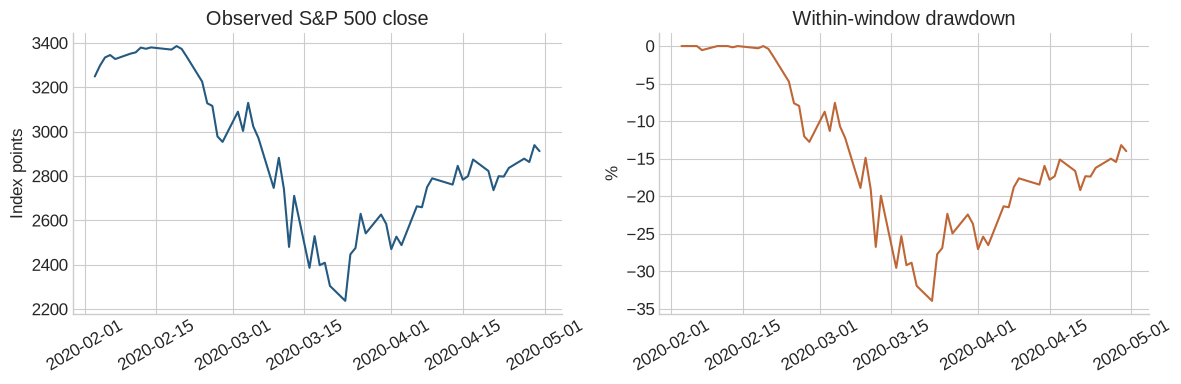

series                                                             SP500
source                          https://fred.stlouisfed.org/series/SP500
window_start                                                  2020-02-03
window_end                                                    2020-04-30
peak_date                                                     2020-02-19
trough_date                                                   2020-03-23
drawdown_magnitude                                               0.33925
multiplier                                                           0.3
external_impairment                                             0.101775
mapping                min(1, selected-window maximum drawdown magnit...
dtype: object

In [4]:
market=market_data(); mapping=calibration(multiplier=.3)
fig, axes=plt.subplots(1,2,figsize=(12,4))
axes[0].plot(market.date,market.close,color='#245a81');axes[0].set_title('Observed S&P 500 close');axes[0].set_ylabel('Index points')
axes[1].plot(market.date,100*market.drawdown,color='#bf6636');axes[1].set_title('Within-window drawdown');axes[1].set_ylabel('%')
for ax in axes: ax.tick_params(axis='x',rotation=30)
plt.tight_layout();plt.show()
display(pd.Series(mapping))

# 6 · Model specification and evaluation plan
$$L_i=q A_i,\quad E_i'=E_i-L_i,\quad q_i^*=E_i/A_i$$

Report (a) bank-level remaining equity; (b) number with nonpositive modeled equity; (c) summed capital shortfall. Assets receive a uniform hypothetical haircut, including categories with different real risk. Liabilities are held fixed. No earnings, recapitalization, hedging, tax or policy response is modeled.

**Verification:** hand calculations; zero-shock control; threshold identity; monotonic exhaustion counts; source checksums; accounting reconciliation.

**Empirical limitation:** the observed June financials are descriptive context, not ground-truth losses from this hypothetical model. No accuracy score is justified.

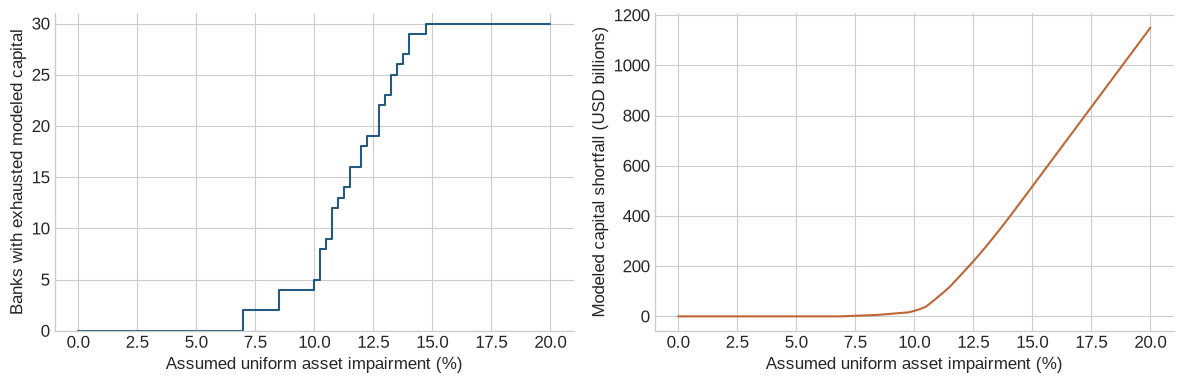

In [5]:
grid=np.linspace(0,.20,81)
rows=[]
for q in grid:
 r=stress(banks,float(q))
 rows.append({'impairment':q,'capital_exhausted':int(r.capital_exhausted.sum()),'capital_shortfall_usd_million':float(r.capital_shortfall.sum())})
sensitivity=pd.DataFrame(rows)
assert sensitivity.capital_exhausted.is_monotonic_increasing
assert stress(banks,0).capital_exhausted.sum()==0
assert np.allclose(stress(banks,0).remaining_equity,banks.equity)
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].step(sensitivity.impairment*100,sensitivity.capital_exhausted,where='post',color='#245a81')
axes[0].set_ylabel('Banks with exhausted modeled capital');axes[0].set_ylim(0,31)
axes[1].plot(sensitivity.impairment*100,sensitivity.capital_shortfall_usd_million/1000,color='#bf6636')
axes[1].set_ylabel('Modeled capital shortfall (USD billions)')
for ax in axes: ax.set_xlabel('Assumed uniform asset impairment (%)')
plt.tight_layout();plt.show()
sensitivity.to_csv(ROOT/'data/processed/stress_sensitivity.csv',index=False)

# 7 · Scenario results and sensitivity
The 0.3 multiplier is illustrative. All results below are conditional on the same static haircut model. Capital exhaustion does not indicate an observed bank failure.

In [6]:
scenarios=[]
for m in [0,.1,.2,.3,.4,.5]:
 q=min(1,m*mapping['drawdown_magnitude']);r=stress(banks,q)
 scenarios.append({'assumed_multiplier':m,'asset_impairment_pct':100*q,'capital_exhausted':int(r.capital_exhausted.sum()),'shortfall_USD_billion':r.capital_shortfall.sum()/1000})
scenario_table=pd.DataFrame(scenarios);display(scenario_table.round(3))
result=stress(banks,mapping['external_impairment'])
display(result.sort_values('remaining_equity')[['NAME','equity_ratio','loss','remaining_equity','capital_exhausted']].head(10).round(3))
result.to_csv(ROOT/'data/processed/scenario_results.csv',index=False)
scenario_table.to_csv(ROOT/'data/processed/market_mapping_scenarios.csv',index=False)

,assumed_multiplier,asset_impairment_pct,capital_exhausted,shortfall_USD_billion
0,0.0,0.000,0,0.000
1,0.1,3.392,0,0.000
2,0.2,6.785,0,0.000
3,0.3,10.177,8,26.607
4,0.4,13.570,26,340.389
5,0.5,16.962,30,765.827


,NAME,equity_ratio,loss,remaining_equity,capital_exhausted
12,CHARLES SCHWAB BANK,0.068,22049.934,-7217.934,True
2,WELLS FARGO BANK NA,0.098,174332.121,-6939.121,True
9,BANK OF NEW YORK MELLON,0.084,31691.374,-5688.374,True
20,NORTHERN TRUST CO,0.069,13829.723,-4479.888,True
26,FIRST REPUBLIC BANK,0.085,11832.717,-1981.610,True
27,DISCOVER BANK,0.101,11437.888,-136.110,True
15,ALLY BANK,0.101,17046.478,-93.478,True
4,U S BANK NATIONAL ASSN,0.102,49463.020,-70.517,True
10,STATE STREET BANK&TRUST CO,0.105,24644.583,806.417,False
17,MORGAN STANLEY BANK NA,0.108,14924.777,979.223,False


# 8 · Contagion mechanism: independent controlled demonstration
The empirical experiment above has **no measured bilateral lending edges**. To explain the implemented network mechanism, use a separate synthetic three-bank chain:

A lends B 100; C lends A 80; recovery is 40%. B is forced to default. A loses 60 against equity 50, then C loses 48 against equity 40. Gross posted losses total 108. A direct-loss-only control stops at 60.

This verifies propagation arithmetic; it does not describe the named FDIC banks. Losses move from debtor to creditor, opposite the lending arrow.

In [7]:
from atlas.models import Bank, Dataset, Exposure, Scenario
from atlas.engine import furfine
chain=Dataset(units='Synthetic monetary units',topology='hand_chain',banks=[
 Bank(id='A',name='A',external_assets=100,interbank_assets=100,interbank_liabilities=80,deposits=70,equity=50),
 Bank(id='B',name='B',external_assets=150,interbank_assets=0,interbank_liabilities=100,deposits=30,equity=20),
 Bank(id='C',name='C',external_assets=20,interbank_assets=80,interbank_liabilities=0,deposits=60,equity=40)],
 exposures=[Exposure(lender='A',borrower='B',amount=100),Exposure(lender='C',borrower='A',amount=80)])
cascade=furfine(chain,Scenario(initial_defaults=['B'],recovery=.4))
assert cascade['default_count']==3 and np.isclose(cascade['interbank_loss'],108)
display(pd.DataFrame(cascade['events']))
display(pd.DataFrame([{'round':r['round'],'new_defaults':', '.join(r['new_defaults']),'cumulative_defaults':r['cumulative_defaults']} for r in cascade['rounds']]))

,round,lender,borrower,ead,loss
0,1,A,B,100.0,60.0
1,2,C,A,80.0,48.0


,round,new_defaults,cumulative_defaults
0,0,B,1
1,1,A,2
2,2,C,3
3,3,,3


# 9 · Findings, contribution and limits
- Observed capital buffers differ across the fixed cohort; the threshold q*=E/A explains the order of modeled exhaustion under a uniform shock.
- Scenario outcomes depend strongly on the chosen asset impairment. A historical market drawdown alone cannot identify that impairment.
- Reported financial changes and conditional stress outcomes answer different questions.
- The reproducible pipeline, audit trail and documented tests are the demonstrated engineering contribution.
- Network reconstruction and empirical contagion validation remain open work. Complete compatible lending/borrowing margins and uncertainty analysis are needed before extending the named-bank experiment.

**Next research milestone:** hold observed margins fixed and compare contagion outcomes across multiple plausible exposure reconstructions. No novelty or superiority is established at this stage.

In [8]:
summary={'cohort_size':len(banks),'baseline':'2019-12-31','followup':'2020-06-30','observed_drawdown':mapping['drawdown_magnitude'],'assumed_multiplier':.3,'assumed_impairment':mapping['external_impairment'],'capital_exhausted':int(result.capital_exhausted.sum()),'shortfall_usd_million':float(result.capital_shortfall.sum()),'chain_loss':cascade['interbank_loss'],'python':platform.python_version(),'inputs_verified':True}
(ROOT/'reports/real_data_summary.json').write_text(json.dumps(summary,indent=2))
display(pd.Series(summary))
print('All notebook assertions passed. Outputs saved under data/processed and reports/.')

cohort_size                        30
baseline                   2019-12-31
followup                   2020-06-30
observed_drawdown             0.33925
assumed_multiplier                0.3
assumed_impairment           0.101775
capital_exhausted                   8
shortfall_usd_million    26607.031624
chain_loss                      108.0
python                        3.12.16
inputs_verified                  True
dtype: object

All notebook assertions passed. Outputs saved under data/processed and reports/.


# 10 · References and reproducibility
- [FDIC API documentation](https://api.fdic.gov/banks/docs) and packaged official field definitions.
- [FRED SP500 series and usage notes](https://fred.stlouisfed.org/series/SP500). The packaged market fixture retains its separate provenance and provider rights.
- [Literature decision review](https://app.undermind.ai/projects/0fc02641-fd90-41a3-bd60-b5043202955b?path=/Atlas%20data%20and%20literature%20decision%20review).
- Literature DOIs on slide 2; methodology and acquisition URLs in `docs/research/PROTOCOL.md` and `data/manifest.json`.

Run all cells from a fresh kernel. Offline replay uses raw snapshots; `scripts/fetch_observed.py` is an explicit online refresh. A refresh changes data vintage and requires re-execution.

**Discussion:** what additional evidence would justify turning this scenario study into a validated contagion model?